# Customers Like You: analysis notebook

GiftLane mini-project: PCA or Truncated SVD for a retail recommendation problem. Solo project, so I hold both the Data Engineer and ML Engineer roles.

**This notebook is standalone.** It starts from the raw Excel file and runs everything top to bottom: load, clean, split, build the matrix, fit the models, evaluate against the best-seller baseline, compare PCA with SVD, and draw the customer map. Variables carry over from cell to cell, so run the cells in order (Run All).

**How to run.** Put `online_retail_II.xlsx` in `data/raw/` and open this notebook from the project root. Reading the Excel file takes a few minutes; everything after that is fast. Random seeds are fixed at 42.

**Privacy (R4).** Customer IDs are used inside the code (to build the matrix and look up countries) but are never printed or plotted. Customer numbers like 0, 1, 2 are matrix row positions, not IDs.

**Units.** MB means 1,000,000 bytes everywhere. A row is one invoice line; a pair is one distinct customer-product combination.

In [1]:
import time
import tracemalloc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

# relative path: the notebook is opened from the project root. UPPER_CASE = constants that never change
RAW = Path("data/raw/online_retail_II.xlsx")

# fixed seed so every run gives the same result (R6)
SEED = 42

# k = 200 is fixed in the SVD section below, before any held-out scoring
K = 200
TOP_N = 10

# a product needs at least this many different buyers in train
MIN_CUSTOMERS = 10
BYTES_PER_MB = 1_000_000

assert RAW.exists(), "Raw file not found: put online_retail_II.xlsx in data/raw/"

**What this cell does:** imports the libraries and sets the constants. The `assert` stops the notebook with a clear message if the raw file is missing.

## 1. Load both sheets and profile the raw data

The Excel file has one sheet per year. I stack them into one table so each customer's full history sits in one place, which the time split and the matrix both need.

In [2]:
# sheet_name=None loads every sheet into a dictionary
sheets = pd.read_excel(RAW, sheet_name=None)

# concat matches columns by NAME, so if the sheets differed it would silently create half-empty columns; assert stops that
cols_first = sheets["Year 2009-2010"].columns.tolist()
cols_second = sheets["Year 2010-2011"].columns.tolist()
assert cols_first == cols_second, "Sheets have different column names"

# stack the two years vertically; ignore_index=True gives clean row numbers
df = pd.concat(list(sheets.values()), ignore_index=True)

# I removed the space from the name so I can use one simple name everywhere
df = df.rename(columns={"Customer ID": "CustomerID"})

print(f"{len(df):,} invoice lines, {df.shape[1]} columns")

1,067,371 invoice lines, 8 columns


In [3]:
# profile: one row per column of df, showing its type and how much is missing
# isna() gives True/False per cell; sum() counts the Trues; mean() gives the share, times 100 for a percentage
profile = pd.DataFrame(
    {
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
    }
)
profile

,dtype,missing,missing_pct
Invoice,object,0,0.00
StockCode,object,0,0.00
Description,object,4382,0.41
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
Price,float64,0,0.00
CustomerID,float64,243007,22.77
Country,str,0,0.00


**Table above:** one row per column of the raw data; columns are its type, how many values are missing, and the missing percentage. `CustomerID` and `Description` have missing values. I leave them missing: a customer cannot be invented, and lines without a customer are dropped in the cleaning step.

In [4]:
# dataset-level facts BEFORE cleaning: counts and dates only, no customer IDs (R4)
summary = pd.Series(
    {
        "rows": len(df),
        "date_min": df["InvoiceDate"].min(),
        "date_max": df["InvoiceDate"].max(),

        # Invoice mixes numbers and text, so astype(str) first; cancellations start with "C"
        "cancellation_lines": df["Invoice"].astype(str).str.startswith("C").sum(),
        "quantity_non_positive": (df["Quantity"] <= 0).sum(),
        "price_non_positive": (df["Price"] <= 0).sum(),

        # nunique() counts distinct values and ignores missing ones
        "distinct_customers": df["CustomerID"].nunique(),
        "distinct_products": df["StockCode"].nunique(),
    },
    name="value",
)
summary

rows                                 1067371
date_min                 2009-12-01 07:45:00
date_max                 2011-12-09 12:50:00
cancellation_lines                     19494
quantity_non_positive                  22950
price_non_positive                      6207
distinct_customers                      5942
distinct_products                       5305
Name: value, dtype: object

In [5]:
# Invoice and StockCode mix numbers and text (cancellations start with C, variants end in a letter),
# so I make them text; turning them into numbers would destroy those flags
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["Description"] = df["Description"].astype(str)

## 2. Clean, with a log of how many lines each rule removed

Five rules, applied in a fixed order. The order changes the per-rule counts but not the final table.

In [6]:
# I save the starting row count first, because every rule's count and the final check depend on it
rows_start = len(df)

# Rule 1: cancellations start with "C". ~ flips True/False, so I keep everything that is NOT a cancellation
is_cancellation = df["Invoice"].str.startswith("C")
df = df[~is_cancellation]
rows_after_cancellations = len(df)
removed_cancellations = rows_start - rows_after_cancellations

# Rule 2: a zero or negative quantity is a return or an adjustment, not a purchase
df = df[df["Quantity"] > 0]
rows_after_quantity = len(df)
removed_quantity = rows_after_cancellations - rows_after_quantity

# Rule 3: a zero or negative price is not a real sale
df = df[df["Price"] > 0]
rows_after_price = len(df)
removed_price = rows_after_quantity - rows_after_price

# Rule 4: a real product code starts with 5 digits (variants like 85123A still match);
# POST, M, D, BANK CHARGES, vouchers and other odd codes don't
df = df[df["StockCode"].str.match(r"^\d{5}")]
rows_after_product_code = len(df)
removed_product_code = rows_after_price - rows_after_product_code

# Rule 5: without a customer I can't put the row in a customer x product matrix
df = df[df["CustomerID"].notna()]
rows_after_customerID = len(df)
removed_customerID = rows_after_product_code - rows_after_customerID

# guard: the script stops if any ID is still missing
assert df["CustomerID"].notna().all(), "There are still rows with no CustomerID"

# CustomerID was float (13085.0) because of the missing values; with none left I can safely make it int
df["CustomerID"] = df["CustomerID"].astype(int)

# the cleaning log: one dictionary per rule, each one becomes one row of the table
log_rows = [
    {"rule": "start", "rows_removed": 0, "rows_remaining": rows_start},
    {"rule": "cancellations", "rows_removed": removed_cancellations, "rows_remaining": rows_after_cancellations},
    {"rule": "quantity", "rows_removed": removed_quantity, "rows_remaining": rows_after_quantity},
    {"rule": "price", "rows_removed": removed_price, "rows_remaining": rows_after_price},
    {"rule": "stockcodes", "rows_removed": removed_product_code, "rows_remaining": rows_after_product_code},
    {"rule": "customerID", "rows_removed": removed_customerID, "rows_remaining": rows_after_customerID},
]
cleaning_log = pd.DataFrame(log_rows)

# I check that the log adds up BEFORE adding the total row, otherwise the total would be counted twice
total_rows_removed = cleaning_log["rows_removed"].sum()
assert (rows_start - total_rows_removed) == len(df), "Cleaning log does not add up"

total_row = pd.DataFrame([
    {"rule": "total", "rows_removed": total_rows_removed, "rows_remaining": rows_after_customerID},
])
cleaning_log = pd.concat([cleaning_log, total_row], ignore_index=True)

# after filtering, df has gaps in its row numbers; I renumber them from 0
df = df.reset_index(drop=True)
cleaning_log

,rule,rows_removed,rows_remaining
0,start,0,1067371
1,cancellations,19494,1047877
2,quantity,3457,1044420
3,price,2750,1041670
4,stockcodes,4793,1036877
5,customerID,234245,802632
6,total,264739,802632


**Table above:** rows are the cleaning rules in order. `rows_removed` is what that rule removed on its own, `rows_remaining` is what is left after it. The assert checks that start minus total removed equals the cleaned table.

## 3. Split by time: the last 2 months are the test period

The cutoff date is computed from the data, not typed by hand (R6). Train is everything before it, test candidates are everything on or after it, so no test row can reach a model (R2).

A **held-out pair** is a (customer, product) combination bought in the test period that the customer **never bought in train**. The box should suggest new products, and counting repeat purchases would make the model look better than it is.

In [7]:
latest_date = df["InvoiceDate"].max()
test_set_cutoff_date = latest_date - pd.DateOffset(months=2)

# the cutoff includes a time of day, so "<" and ">=" are exact opposites: every row lands on exactly one side
is_train = df["InvoiceDate"] < test_set_cutoff_date
is_test_candidates = df["InvoiceDate"] >= test_set_cutoff_date

train = df[is_train]
test_candidates = df[is_test_candidates]

# guards: no test-period row in train, and no row goes missing
assert train["InvoiceDate"].max() < test_set_cutoff_date, "Train contains rows on or after the cutoff"
assert len(train) + len(test_candidates) == len(df), "Train and test rows do not add up to the full data"

# I only need "did this customer ever buy this product?", so I drop repeated pairs
train_pairs = train[["CustomerID", "StockCode"]].drop_duplicates()
test_pairs = test_candidates[["CustomerID", "StockCode"]].drop_duplicates()
pairs_all = len(test_pairs)

# a left merge labels each test pair: "both" = already bought in train (a repeat), "left_only" = new for this customer
merged = test_pairs.merge(train_pairs, on=["CustomerID", "StockCode"], how="left", indicator=True)
is_new = merged["_merge"] == "left_only"
new_test_pairs = merged[is_new].drop(columns="_merge")
pairs_after_removing_repeats = len(new_test_pairs)

# customers with no training history have nothing to recommend from (in real life they would see best sellers)
train_customers = train["CustomerID"].unique()
new_test_pairs = new_test_pairs[new_test_pairs["CustomerID"].isin(train_customers)]
pairs_after_removing_new_customers = len(new_test_pairs)

# a product that never appears in train has no column, so it can never be recommended
train_products = train["StockCode"].unique()
new_test_pairs = new_test_pairs[new_test_pairs["StockCode"].isin(train_products)]
pairs_after_removing_new_products = len(new_test_pairs)

# counts only, no customer IDs
summary_counts = {
    "cutoff": str(test_set_cutoff_date),
    "train_rows": len(train),
    "test_candidate_rows": len(test_candidates),
    "test_pairs_all": pairs_all,
    "after_removing_repeats": pairs_after_removing_repeats,
    "after_removing_new_customers": pairs_after_removing_new_customers,
    "after_removing_new_products": pairs_after_removing_new_products,
    "test_customers": new_test_pairs["CustomerID"].nunique(),
}
split_summary = pd.DataFrame(summary_counts.items(), columns=["item", "value"])
split_summary

,item,value
0,cutoff,2011-10-09 12:50:00
1,train_rows,684069
2,test_candidate_rows,118563
3,test_pairs_all,95018
4,after_removing_repeats,63252
5,after_removing_new_customers,49423
6,after_removing_new_products,45753
7,test_customers,1916


In [8]:
# the funnel with each percentage stated against its own base
funnel = [
    ("removed repeats of train purchases", pairs_all, pairs_after_removing_repeats),
    ("removed customers with no train history", pairs_after_removing_repeats, pairs_after_removing_new_customers),
    ("removed products never seen in train", pairs_after_removing_new_customers, pairs_after_removing_new_products),
]
for label, before, after in funnel:
    print(f"{label}: {before - after:,} of {before:,} ({(before - after) / before:.0%} of {before:,})")

# repeat purchases inside train: lines shrink to distinct pairs
print(f"Train: {len(train):,} lines shrink to {len(train_pairs):,} distinct pairs, "
      f"so {1 - len(train_pairs) / len(train):.0%} of lines are repeat purchases")

removed repeats of train purchases: 31,766 of 95,018 (33% of 95,018)
removed customers with no train history: 13,829 of 63,252 (22% of 63,252)
removed products never seen in train: 3,670 of 49,423 (7% of 49,423)
Train: 684,069 lines shrink to 417,719 distinct pairs, so 39% of lines are repeat purchases


**Reading this:** the first table is the counts at each step. The funnel shows how many held-out pairs each step removed and the base for its percentage. Customers with no train history are the cold-start group: they should see best sellers.

## 4. Build the sparse customer x product matrix (train only)

- rows = customers, columns = products, cell = how much that customer bought of that product;
- a cell holds `log1p` of the summed quantity, so one huge order doesn't dominate but bigger buying still counts for more;
- only products with at least 10 different buyers in train are kept (counted on train only);
- stored sparse: only the filled cells are kept.

In [9]:
# one row per customer-product pair
pair_quantities = train.groupby(["CustomerID", "StockCode"])["Quantity"].sum().reset_index()

# each pair is one customer, so counting a product's rows gives its number of buyers
customers_per_product = pair_quantities["StockCode"].value_counts()

# keep only products with enough buyers, counted on train only
kept_products = customers_per_product[customers_per_product >= MIN_CUSTOMERS].index
pair_quantities = pair_quantities[pair_quantities["StockCode"].isin(kept_products)].reset_index(drop=True)

# log1p so one huge order doesn't dominate a cell; 1 + keeps a quantity of 1 above zero
pair_quantities["Value"] = np.log1p(pair_quantities["Quantity"])

# each customer and each product once, in order of first appearance
customer_ids = pair_quantities["CustomerID"].unique()
product_ids = pair_quantities["StockCode"].unique()

# the matrix only knows positions, so each ID gets a row or column number
customer_to_row = {}
for i, c in enumerate(customer_ids):
    customer_to_row[c] = i

product_to_col = {}
for j, p in enumerate(product_ids):
    product_to_col[p] = j

rows = pair_quantities["CustomerID"].map(customer_to_row)
cols = pair_quantities["StockCode"].map(product_to_col)

# one filled cell per pair; shape is needed because empty cells are not listed
matrix = sp.csr_matrix(
    (pair_quantities["Value"], (rows, cols)),
    shape=(len(customer_ids), len(product_ids)),
)

# position in each list = row or column number
customer_index = pd.DataFrame({"CustomerID": customer_ids})
product_index = pd.DataFrame({"StockCode": product_ids})

# the held-out pairs: a pair can only be scored if its customer has a row and its product has a column
test_pairs = new_test_pairs
does_customer_have_row = test_pairs["CustomerID"].isin(customer_to_row)
does_product_have_col = test_pairs["StockCode"].isin(product_to_col)
test_pairs = test_pairs[does_customer_have_row & does_product_have_col].reset_index(drop=True)

n_customers, n_products = matrix.shape
print(f"{n_customers:,} x {n_products:,} matrix and {len(test_pairs):,} held-out pairs")

5,473 x 3,687 matrix and 44,727 held-out pairs


In [10]:
# matrix report: MB means 1,000,000 bytes; sparsity is divide first, then subtract from 1;
# sparse MB adds data, indices and indptr, because the matrix needs all three
n_products_in_train = train["StockCode"].nunique()
report_counts = {
    "products_in_train": n_products_in_train,
    "products_kept": n_products,
    "customers_rows": n_customers,
    "products_columns": n_products,
    "filled_cells": matrix.nnz,
    "sparsity": round(1 - matrix.nnz / (n_customers * n_products), 4),
    "dense_mb": round(n_customers * n_products * 8 / 1e6, 2),
    "sparse_mb": round((matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1e6, 2),
    "heldout_pairs": len(test_pairs),
    "heldout_customers": test_pairs["CustomerID"].nunique(),
}

# each (label, number) pair from the dict becomes one row of the table
report_rows = []
for item, value in report_counts.items():
    report_rows.append({"item": item, "value": str(value)})
matrix_report = pd.DataFrame(report_rows)
matrix_report

,item,value
0,products_in_train,4529
1,products_kept,3687
2,customers_rows,5473
3,products_columns,3687
4,filled_cells,413927
5,sparsity,0.9795
6,dense_mb,161.43
7,sparse_mb,4.99
8,heldout_pairs,44727
9,heldout_customers,1913


In [11]:
dropped = n_products_in_train - n_products
print(f"Product filter: {dropped:,} of {n_products_in_train:,} products dropped ({dropped / n_products_in_train:.0%} of {n_products_in_train:,})")
print(f"Held-out pairs after the filter: {len(new_test_pairs):,} shrink to {len(test_pairs):,} "
      f"({len(new_test_pairs) - len(test_pairs):,} dropped, {(len(new_test_pairs) - len(test_pairs)) / len(new_test_pairs):.0%} of {len(new_test_pairs):,})")

Product filter: 842 of 4,529 products dropped (19% of 4,529)
Held-out pairs after the filter: 45,753 shrink to 44,727 (1,026 dropped, 2% of 45,753)


**Table above:** rows are facts about the matrix, one value each. The matrix is almost all zeros, so the sparse version is far smaller than the full grid. That is also why Truncated SVD fits: it works on the matrix as it is.

## 5. Method choice: Truncated SVD as the main model (decided before any fitting)

PCA is run later at the same k for comparison.

- The matrix is mostly empty and SVD works on it directly.
- One SVD fit gives customer factors and product factors together, which is what a recommender needs.
- PCA first subtracts the column averages, so it describes how each customer differs from the *average customer*. SVD describes which products are bought together by the same customers.
- scikit-learn can run PCA on sparse input with implicit centring (`svd_solver="arpack"`), so it is possible, but it still answers the "difference from the average" question. That is why PCA is the comparison and not the main model.
- The cost I accept: SVD doesn't subtract the average, so component 1 will probably show how much a customer buys. I also get no "% of variance kept", only the reconstruction error.

## 6. Fit Truncated SVD for five values of k and choose k

**Relative reconstruction error** = size of what is lost / size of the whole matrix. "Size" is the Frobenius norm: square every filled cell, add up, take the root. Zeros add nothing, so `.data` (the filled cells only) is enough. The lost size comes from Pythagoras (whole squared = rebuilt squared + lost squared), so I never rebuild the dense matrix.

In [12]:
K_VALUES = [10, 20, 50, 100, 200]

matrix_size = np.sqrt((matrix.data ** 2).sum())

# one dict per k goes into this list, and the list becomes the table
rows = []
for k in K_VALUES:
    # random_state keeps the result the same every run (R6)
    svd = TruncatedSVD(n_components=k, random_state=SEED)

    # learns k patterns and returns one short row of k numbers per customer
    customer_factors = svd.fit_transform(matrix)

    # size of the rebuilt part: square, add, root for the customer factors
    rebuilt_size = np.sqrt((customer_factors ** 2).sum())

    # the size of what we actually lost, using Pythagoras
    lost_size = np.sqrt(matrix_size ** 2 - rebuilt_size ** 2)

    rows.append({
        "k": k,
        "relative_error": round(lost_size / matrix_size, 4),
    })

errors = pd.DataFrame(rows)
errors

,k,relative_error
0,10,0.8761
1,20,0.8459
2,50,0.7897
3,100,0.7278
4,200,0.6395


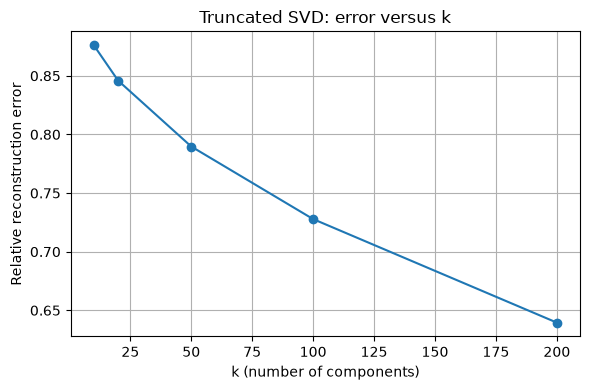

k = 200: relative error 0.6395, so about 64% of the matrix is not rebuilt
Stored factors 14.66 MB against 161.43 MB dense


In [13]:
plt.figure(figsize=(6, 4))
plt.plot(errors["k"], errors["relative_error"], marker="o")
plt.xlabel("k (number of components)")
plt.ylabel("Relative reconstruction error")
plt.title("Truncated SVD: error versus k")
plt.grid(True)
plt.tight_layout()
plt.show()

# stored factors: customer factors (customers x k) plus product factors (products x k), 8 bytes per number
factors_mb = K * (n_customers + n_products) * 8 / BYTES_PER_MB
error_at_k = float(errors.loc[errors["k"] == K, "relative_error"].iloc[0])
print(f"k = {K}: relative error {error_at_k:.4f}, so about {error_at_k:.0%} of the matrix is not rebuilt")
print(f"Stored factors {factors_mb:.2f} MB against {report_counts['dense_mb']:,.2f} MB dense")

**Decision: k = 200.** The curve has no elbow, so I took the lowest error of the five, and the stored factors stay small. Reconstruction error measures how well the *training table is copied*. It does **not** measure recommendation quality: a lower error does not prove better suggestions. The hit rate below tests that.

k is fixed here, **before any held-out scoring**, and must not be changed after seeing the hit rates. Changing it afterwards would leak the test set into the model choice (R2).

## 7. The recommender: similar products and top 10 for a customer

Each product gets a *fingerprint* of 200 numbers (a row of `svd.components_.T`), scaled to length 1. Multiplying two fingerprints then gives their cosine similarity, which compares direction and not size, so popular products don't look similar to everything. Two products are "similar" when the same customers buy them, because the fingerprints are learned only from the customer x product matrix.

In [14]:
# k = 200 was fixed above before any held-out scoring
svd = TruncatedSVD(n_components=K, random_state=SEED)
svd.fit(matrix)

# one row per product (products x 200), each scaled to length 1,
# so a plain multiplication of two rows is their cosine similarity
product_vectors = normalize(svd.components_.T)
print(product_vectors.shape)


def similar_products(product_number, n=TOP_N):
    # multiplying by one product's fingerprint scores every product against it
    scores = product_vectors @ product_vectors[product_number]
    # a product is always most similar to itself, so I rule it out
    scores[product_number] = -np.inf
    return np.argsort(-scores)[:n]


def recommend(customer_number, n=TOP_N):
    customer_row = matrix[customer_number]
    # add up the fingerprints of what they bought, weighted by their matrix values
    profile = (customer_row @ product_vectors).ravel()
    # score every product by how close it is to that profile
    scores = product_vectors @ profile
    # .indices are the column numbers of products they already bought
    scores[customer_row.indices] = -np.inf
    return np.argsort(-scores)[:n]

(3687, 200)


In [15]:
# product names are only for reading the results (they are not customer IDs)
product_names = (
    df.drop_duplicates("StockCode")
    .set_index("StockCode")["Description"]
    .loc[product_index["StockCode"]]
    .astype(str).str.strip()
    .to_numpy()
)

# a quick look: product 0 and its 10 most similar products
print("Product:", product_names[0])
for column_number in similar_products(0):
    print("   ", product_names[column_number])

Product: EDWARDIAN PARASOL BLACK
    EDWARDIAN PARASOL NATURAL
    EDWARDIAN PARASOL RED
    EDWARDIAN PARASOL PINK
    BLACK/BLUE DOTS RUFFLED UMBRELLA
    RED/WHITE DOTS RUFFLED UMBRELLA
    PINK/BROWN DOTS RUFFLED UMBRELLA
    BLUE/BROWN DOTS RUFFLED UMBRELLA
    FAIRY CAKES  WALL THERMOMETER
    FOLDING UMBRELLA  CHOC/WHITE  SPOT
    PINK OVAL JEWELLED MIRROR


**Sanity check, not a test of quality:** the products listed should look like close relatives of the first one (colour variants and similar items). Variants of one product can fill a list, which is a risk for the memo.

## 8. Evaluate on held-out purchases and time the nightly job

- **Hit rate at 10** = the share of test customers for whom at least one of their 10 suggestions is a held-out product (something they really bought in the test period and never before).
- **Baseline:** the 10 best-selling products (most distinct buyers in train) that the customer has not already bought. Same customers, same held-out pairs, train only.
- The nightly job is timed in three parts: the fit, the box for all products, and the top 10 for all customers. The held-out pairs are loaded **only after** the timed part (R2).

In [16]:
# part 1: fit SVD and build the product fingerprints (length 1 each)
start = time.perf_counter()
svd = TruncatedSVD(n_components=K, random_state=SEED)
svd.fit(matrix)
product_vectors = normalize(svd.components_.T)
fit_seconds = time.perf_counter() - start

# part 2: the "customers who bought this also bought" box for all products
start = time.perf_counter()
product_scores = product_vectors @ product_vectors.T
# a product must not recommend itself
np.fill_diagonal(product_scores, -np.inf)
similar_top = np.argsort(-product_scores, axis=1)[:, :TOP_N]
all_products_seconds = time.perf_counter() - start

# part 3: top 10 new products for all customers
start = time.perf_counter()
# one taste profile per customer
customer_profiles = matrix @ product_vectors
customer_scores = customer_profiles @ product_vectors.T
# rule out everything each customer already bought
bought_rows, bought_columns = matrix.nonzero()
customer_scores[bought_rows, bought_columns] = -np.inf
customer_top = np.argsort(-customer_scores, axis=1)[:, :TOP_N]
all_customers_seconds = time.perf_counter() - start

print(f"fit {fit_seconds:.2f} s, all products {all_products_seconds:.2f} s, all customers {all_customers_seconds:.2f} s")

fit 0.42 s, all products 0.80 s, all customers 1.20 s


In [17]:
# ---- evaluation: the held-out pairs are used only now ----

# the position in each index is the matrix row or column number
customer_row_of = {}
for row_number, customer_id in enumerate(customer_index["CustomerID"]):
    customer_row_of[customer_id] = row_number

product_column_of = {}
for column_number, stock_code in enumerate(product_index["StockCode"]):
    product_column_of[stock_code] = column_number

# the matrix step already dropped pairs with no row or column, so no KeyError is expected
test_rows = [customer_row_of[c] for c in test_pairs["CustomerID"]]
test_columns = [product_column_of[p] for p in test_pairs["StockCode"]]

# True where a customer bought a product in the test period that is new to them
held_out = np.zeros(matrix.shape, dtype=bool)
held_out[test_rows, test_columns] = True

test_customers = np.unique(test_rows)

# model: does any of the customer's 10 suggestions sit in their held-out products?
model_recommendations = customer_top[test_customers]
model_hit = held_out[test_customers[:, None], model_recommendations].any(axis=1)
model_hit_rate = model_hit.mean()

# baseline: the 10 best sellers (most distinct buyers in train) the customer has not bought
buyers_per_product = matrix.getnnz(axis=0)
# stable sort so ties always come out in the same order (R6)
best_sellers_ranked = np.argsort(-buyers_per_product, kind="stable")

baseline_hits = 0
for row in test_customers:
    bought = set(matrix[row].indices)
    picks = []
    for column in best_sellers_ranked:
        if column not in bought:
            picks.append(column)
        if len(picks) == TOP_N:
            break
    if held_out[row, picks].any():
        baseline_hits += 1
baseline_hit_rate = baseline_hits / len(test_customers)

results = [
    {"measure": "k", "value": K},
    {"measure": "test_customers", "value": len(test_customers)},
    {"measure": "heldout_pairs", "value": len(test_pairs)},
    {"measure": "hit_rate_at_10_svd", "value": round(model_hit_rate, 4)},
    {"measure": "hit_rate_at_10_best_sellers", "value": round(baseline_hit_rate, 4)},
    {"measure": "fit_seconds", "value": round(fit_seconds, 2)},
    {"measure": "all_products_seconds", "value": round(all_products_seconds, 2)},
    {"measure": "all_customers_seconds", "value": round(all_customers_seconds, 2)},
]
pd.DataFrame(results)

,measure,value
0,k,200.0000
1,test_customers,1913.0000
2,heldout_pairs,44727.0000
3,hit_rate_at_10_svd,0.2148
4,hit_rate_at_10_best_sellers,0.2687
5,fit_seconds,0.4200
6,all_products_seconds,0.8000
7,all_customers_seconds,1.2000


In [18]:
gap = baseline_hit_rate - model_hit_rate
total_seconds = fit_seconds + all_products_seconds + all_customers_seconds

print(f"Hit rate at 10: SVD {model_hit_rate:.4f} vs best sellers {baseline_hit_rate:.4f} ({len(test_customers):,} test customers)")
if model_hit_rate > baseline_hit_rate:
    print(f"SVD is ahead by {-gap:.4f}")
else:
    print(f"SVD does NOT beat the baseline: the best-seller list is ahead by {gap:.4f} ({gap * 100:.1f} percentage points)")
print(f"Nightly job: about {total_seconds:.1f} s in total (single run on this machine)")

Hit rate at 10: SVD 0.2148 vs best sellers 0.2687 (1,913 test customers)
SVD does NOT beat the baseline: the best-seller list is ahead by 0.0538 (5.4 percentage points)
Nightly job: about 2.4 s in total (single run on this machine)


**How to read the result honestly:** if SVD scores below the best sellers, success target 3 is not met, and that is reported as measured. I do not change k to chase a better number (that would be test-set leakage).

Untested ideas for a loss: the held-out products are new to each customer, and popular products are bought by many people, so best sellers hit often, while suggestions built from a customer's own history lean toward niche products. This is one time split and one run, so it is a measurement on this split, not a proven difference. Timings are single runs and wobble slightly; the hit rates do not.

**Memory caveat:** the stored factors are small (section 6), but the scoring above builds dense score tables (customers x products, and products x products). Batching would fix that. The whole job does not run in the size of the stored factors.

## 9. PCA versus Truncated SVD at the same k

Both are fitted on the same train-only matrix at k = 200 (seed 42). PCA uses the `arpack` solver, which centres the sparse matrix implicitly, so the matrix is never made dense. Both are scored the same way (fingerprints scaled to length 1, taste profile from the plain matrix row, bought products excluded), so only the fingerprints differ.

In [19]:
# fit Truncated SVD, timed, with peak memory
tracemalloc.start()
start = time.perf_counter()
svd = TruncatedSVD(n_components=K, random_state=SEED)
svd_customer_factors = svd.fit_transform(matrix)
svd_fit_seconds = time.perf_counter() - start
svd_peak_mb = tracemalloc.get_traced_memory()[1] / BYTES_PER_MB
tracemalloc.stop()

# fit PCA (implicit centring on sparse input), same k, same timing
tracemalloc.start()
start = time.perf_counter()
pca = PCA(n_components=K, svd_solver="arpack", random_state=SEED)
pca.fit(matrix)
pca_fit_seconds = time.perf_counter() - start
pca_peak_mb = tracemalloc.get_traced_memory()[1] / BYTES_PER_MB
tracemalloc.stop()

# stored factors: k x (customers + products) x 8 bytes
svd_factors_mb = K * (n_customers + n_products) * 8 / BYTES_PER_MB
# PCA also stores the column-average vector (one number per product)
pca_factors_mb = (K * (n_customers + n_products) + n_products) * 8 / BYTES_PER_MB

# SVD: relative reconstruction error, same formula as above
rebuilt_size = np.sqrt((svd_customer_factors ** 2).sum())
lost_size = np.sqrt(matrix_size ** 2 - rebuilt_size ** 2)
svd_relative_error = lost_size / matrix_size
pca_variance_explained = pca.explained_variance_ratio_.sum()

print(f"SVD fit {svd_fit_seconds:.2f} s, PCA fit {pca_fit_seconds:.2f} s")

SVD fit 0.42 s, PCA fit 0.66 s


**Peak memory** is measured with `tracemalloc`, which sees only memory allocated by Python and NumPy, not memory inside compiled solver code, so it may be undercounted. The caveat is the same for both methods, so I treat the two as about equal and do not claim that PCA needs less.

In [20]:
def hit_rate_at_10(product_vectors):
    # same scoring for both methods: only the fingerprints differ
    scores = (matrix @ product_vectors) @ product_vectors.T
    scores[matrix.nonzero()] = -np.inf
    top = np.argsort(-scores[test_customers], axis=1)[:, :TOP_N]
    hits = held_out[test_customers[:, None], top].any(axis=1)
    return hits.mean()


svd_hit_rate = hit_rate_at_10(normalize(svd.components_.T))
pca_hit_rate = hit_rate_at_10(normalize(pca.components_.T))

# my fresh SVD number should match the one from the evaluation above (if not, something changed)
assert abs(svd_hit_rate - model_hit_rate) < 0.0005

**Component 1 in words.** I check what component 1 really measures instead of guessing: how its customer score relates to how many products a customer bought and to their total log-quantity, and which products load highest. The sign of a component is arbitrary, so I flip it so that bigger means "buys more".

In [21]:
products_bought = matrix.getnnz(axis=1)
total_bought = np.asarray(matrix.sum(axis=1)).ravel()

# PCA's centring done by hand, so the sparse matrix is never made dense
pca_scores = matrix @ pca.components_.T - pca.mean_ @ pca.components_.T

component_1_corr = {}
for label, scores_1, loadings_1 in [
    ("SVD", svd_customer_factors[:, 0], svd.components_[0]),
    ("PCA", pca_scores[:, 0], pca.components_[0]),
]:
    corr_products = np.corrcoef(scores_1, products_bought)[0, 1]
    corr_total = np.corrcoef(scores_1, total_bought)[0, 1]
    sign = 1 if corr_products >= 0 else -1
    component_1_corr[label] = corr_total * sign
    print(label, f"corr with products bought: {corr_products * sign:.3f}",
          f"corr with total log-quantity: {corr_total * sign:.3f}")
    for column_number in np.argsort(-sign * loadings_1)[:5]:
        print("   ", product_index["StockCode"].iloc[column_number], product_names[column_number])

SVD corr with products bought: 0.893 corr with total log-quantity: 0.968
    21212 PACK OF 72 RETRO SPOT CAKE CASES
    85123A WHITE HANGING HEART T-LIGHT HOLDER
    85099B JUMBO BAG RED WHITE SPOTTY
    20725 LUNCH BAG RED SPOTTY
    84991 60 TEATIME FAIRY CAKE CASES
PCA corr with products bought: 0.889 corr with total log-quantity: 0.968
    21212 PACK OF 72 RETRO SPOT CAKE CASES
    85099B JUMBO BAG RED WHITE SPOTTY
    20725 LUNCH BAG RED SPOTTY
    85123A WHITE HANGING HEART T-LIGHT HOLDER
    84991 60 TEATIME FAIRY CAKE CASES


In [22]:
# the comparison table from the brief; the component-1 sentence uses the correlations measured just above
COMPONENT_1_PCA = (
    f"Mostly overall buying volume: correlation {component_1_corr['PCA']:.2f} with a customer's total "
    "log-quantity; top products are the best sellers"
)
COMPONENT_1_SVD = (
    f"Overall buying volume: correlation {component_1_corr['SVD']:.2f} with a customer's total "
    "log-quantity; top products are the best sellers"
)

rows = [
    {"measure": "k used", "pca": K, "truncated_svd": K},
    {"measure": "fit_seconds", "pca": round(pca_fit_seconds, 2), "truncated_svd": round(svd_fit_seconds, 2)},
    {"measure": "peak_memory_mb", "pca": round(pca_peak_mb, 1), "truncated_svd": round(svd_peak_mb, 1)},
    {"measure": "stored_factors_mb", "pca": round(pca_factors_mb, 2), "truncated_svd": round(svd_factors_mb, 2)},
    {"measure": "variance_explained", "pca": round(pca_variance_explained, 4), "truncated_svd": "not used"},
    {"measure": "relative_reconstruction_error", "pca": "not used", "truncated_svd": round(svd_relative_error, 4)},
    {"measure": "hit_rate_at_10", "pca": round(pca_hit_rate, 4), "truncated_svd": round(svd_hit_rate, 4)},
    {"measure": "best_seller_hit_rate_at_10", "pca": round(baseline_hit_rate, 4), "truncated_svd": round(baseline_hit_rate, 4)},
    {"measure": "component_1_in_words", "pca": COMPONENT_1_PCA, "truncated_svd": COMPONENT_1_SVD},
]
pca_vs_svd = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
pca_vs_svd

,measure,pca,truncated_svd
0,k used,200,200
1,fit_seconds,0.66,0.42
2,peak_memory_mb,31.1,34.2
3,stored_factors_mb,14.69,14.66
4,variance_explained,0.5748,not used
5,relative_reconstruction_error,not used,0.6395
6,hit_rate_at_10,0.218,0.2148
7,best_seller_hit_rate_at_10,0.2687,0.2687
8,component_1_in_words,Mostly overall buying volume: correlation 0.97 with a customer's total log-quantity; top products are the best sellers,Overall buying volume: correlation 0.97 with a customer's total log-quantity; top products are the best sellers


In [23]:
difference = abs(pca_hit_rate - svd_hit_rate)
print(f"Hit rate at 10: PCA {pca_hit_rate:.4f}, SVD {svd_hit_rate:.4f}, best sellers {baseline_hit_rate:.4f}")
print(f"PCA vs SVD gap: {difference:.4f}, about {difference * len(test_customers):.0f} of {len(test_customers):,} test customers")

Hit rate at 10: PCA 0.2180, SVD 0.2148, best sellers 0.2687
PCA vs SVD gap: 0.0031, about 6 of 1,913 test customers


**Table above:** rows are the measures from the brief; the columns are PCA and Truncated SVD. Reading it:

- The two quality numbers are different things and must **not** be subtracted: PCA reports *variance explained* (how much of the spread around the average customer is kept), SVD reports *reconstruction error* (how much of the matrix is lost).
- A hit-rate gap of a handful of customers is too small to call a difference. If both sit below the best-seller baseline, both lose.
- Stored factors are almost identical (PCA also stores one column-average number per product).

## 10. Customer map: 2 components, k-means groups, names

This uses a **separate** Truncated SVD with 2 components (not the k = 200 model). Each customer gets two scores, which are the x and y of one dot. Customers are grouped with k-means for 3 to 6 groups, and I keep the number of groups with the highest silhouette score (how well separated the groups are; the brief names no measure, so this is my choice).

In [24]:
GROUP_OPTIONS = [3, 4, 5, 6]
TOP_PRODUCTS = 5
TOP_COUNTRIES = 3

# two scores per customer: one dot on the map (x, y)
svd_map = TruncatedSVD(n_components=2, random_state=SEED)
customer_points = svd_map.fit_transform(matrix)

# try 3 to 6 groups, keep the one with the best silhouette score
choice_rows = []
best_score = -1.0
for n_groups in GROUP_OPTIONS:
    model = KMeans(n_clusters=n_groups, n_init=10, random_state=SEED)
    labels = model.fit_predict(customer_points)
    score = silhouette_score(customer_points, labels)
    choice_rows.append({"n_groups": n_groups, "silhouette": round(score, 4)})
    if score > best_score:
        best_score = score
        best_n_groups = n_groups
        best_labels = labels

pd.DataFrame(choice_rows)

,n_groups,silhouette
0,3,0.6814
1,4,0.5562
2,5,0.5384
3,6,0.5619


In [25]:
# country per customer (descriptive only; the first country listed for each customer)
country_of = df.drop_duplicates("CustomerID").set_index("CustomerID")["Country"]
customer_country = country_of.loc[customer_index["CustomerID"]].to_numpy()

# share of ALL customers who bought each product
share_overall = matrix.getnnz(axis=0) / matrix.shape[0]

profile_rows = []
for group in range(best_n_groups):
    members = np.where(best_labels == group)[0]
    group_matrix = matrix[members]

    # share of THIS group who bought each product, minus the overall share:
    # best sellers are bought by everyone, so they don't make the top list
    share_in_group = group_matrix.getnnz(axis=0) / len(members)
    extra_share = share_in_group - share_overall
    top_columns = np.argsort(-extra_share)[:TOP_PRODUCTS]

    top_product_names = []
    for column_number in top_columns:
        top_product_names.append(product_names[column_number])

    country_shares = pd.Series(customer_country[members]).value_counts(normalize=True)
    top_country_texts = []
    for country, share in country_shares.head(TOP_COUNTRIES).items():
        top_country_texts.append(f"{country} {share:.0%}")

    profile_rows.append({
        "group": group,
        "customers": len(members),
        "share_of_customers": round(len(members) / matrix.shape[0], 4),
        "avg_products_bought": round(group_matrix.getnnz(axis=1).mean(), 1),
        "top_products": "; ".join(top_product_names),
        "top_countries": "; ".join(top_country_texts),
    })

segment_profiles = pd.DataFrame(profile_rows)
segment_profiles

,group,customers,share_of_customers,avg_products_bought,top_products,top_countries
0,0,4748,0.8675,48.3,AMBER GLASS TASSLE BAG CHARM; WHITE HYDRANGEA ART FLOWER; BROWN ANTIQUE CUBE CANDLE; ANT COPPER TURQ BOUDICCA BRACELET; PURPLE GLASS TASSLE BAG CHARM,United Kingdom 92%; Germany 1%; France 1%
1,1,712,0.1301,238.4,PACK OF 72 RETRO SPOT CAKE CASES; LUNCH BAG RED SPOTTY; JUMBO BAG RED WHITE SPOTTY; LUNCHBAG SPACEBOY DESIGN; LUNCHBAG PINK RETROSPOT,United Kingdom 88%; Germany 4%; France 2%
2,2,13,0.0024,1146.2,WALL TIDY RETROSPOT; ROUND CONTAINER SET OF 5 RETROSPOT; LUNCH BAG WOODLAND; JUMBO BAG PINK WITH WHITE SPOTS; LUNCH BAG BLACK SKULL.,United Kingdom 69%; EIRE 15%; Australia 8%


**Table above:** one row per group (rows = groups, columns = size, average distinct products per customer, top products, top countries). Top products are the ones where the group's share of buyers is furthest above everyone's share, because plain best sellers would appear in every list.

**Name the groups from this table.** The names below are my reading of size, products per customer, top products and countries. They go in the next cell. Groups are numbered by k-means (the numbers are the same on every run because the seed is fixed); if a rerun ever gives a different order, check the names against the table before using them.

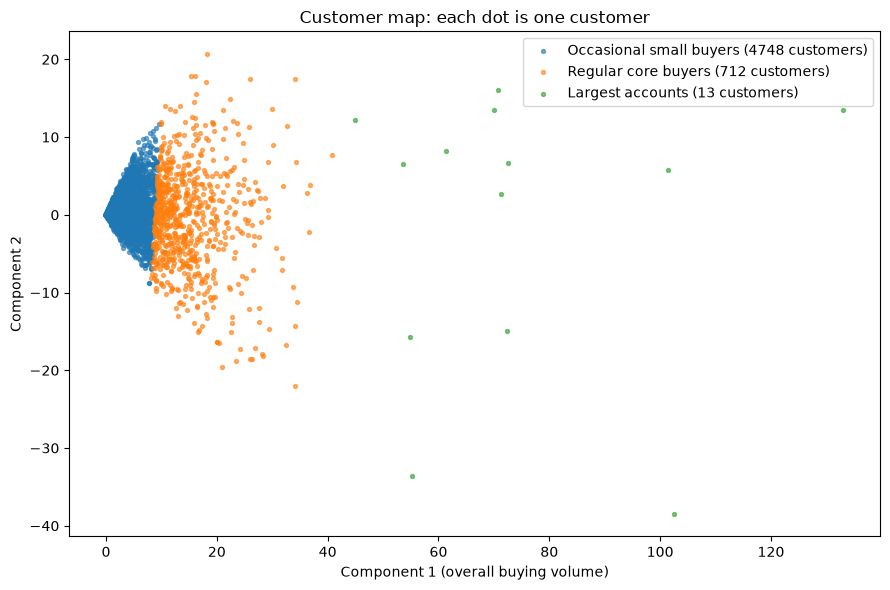

In [26]:
# I name these after reading segment_profiles (size, products per customer, top products, countries);
# "wholesale" is not used, because the data does not show who is a wholesaler
SEGMENT_NAMES = {
    0: "Occasional small buyers",
    1: "Regular core buyers",
    2: "Largest accounts",
}

# the map: one dot per customer, no labels, no IDs (R4)
fig, ax = plt.subplots(figsize=(9, 6))
for group in range(best_n_groups):
    in_group = best_labels == group
    segment_name = SEGMENT_NAMES.get(group, f"Segment {group + 1}")
    ax.scatter(
        customer_points[in_group, 0],
        customer_points[in_group, 1],
        s=8,
        alpha=0.6,
        label=f"{segment_name} ({in_group.sum()} customers)",
    )
ax.set_xlabel("Component 1 (overall buying volume)")
ax.set_ylabel("Component 2")
ax.set_title("Customer map: each dot is one customer")
ax.legend()
fig.tight_layout()
plt.show()

**Reading the map:**
- The dots stretch along component 1, which is overall buying volume, so the groups are mostly **volume tiers**: they differ in how much a customer buys more than in what they buy.
- A very small group is a limit of using only 2 components, not a finding about taste. Read its country shares against its tiny size.
- The biggest group is most of all customers, so its top-product list should not be over-read.
- The figure has no labels on dots and no customer IDs (R4).

## 11. Findings against the success targets

In [27]:
print(f"1. Much smaller: stored factors {svd_factors_mb:.2f} MB vs {report_counts['dense_mb']:,.2f} MB dense "
      f"(the scoring step still builds dense score tables, see the caveat above)")
print(f"2. Fast nightly job: about {total_seconds:.1f} s in total (single run)")
print(f"3. Beats best sellers: {'YES' if model_hit_rate > baseline_hit_rate else 'NO'} "
      f"(SVD {model_hit_rate:.4f}, PCA {pca_hit_rate:.4f}, best sellers {baseline_hit_rate:.4f})")
print(f"4. Nameable groups: {best_n_groups} groups chosen by silhouette; mostly volume tiers (see the map)")

1. Much smaller: stored factors 14.66 MB vs 161.43 MB dense (the scoring step still builds dense score tables, see the caveat above)
2. Fast nightly job: about 2.4 s in total (single run)
3. Beats best sellers: NO (SVD 0.2148, PCA 0.2180, best sellers 0.2687)
4. Nameable groups: 3 groups chosen by silhouette; mostly volume tiers (see the map)


## 12. What could go wrong (each percentage with its base)

The percentages are printed in sections 3 and 4. In words:

- **Repeat purchases are excluded from the test.** A share of test-period pairs were repeats of earlier purchases, so the "new products only" test is harder than a real product page might be.
- **Cold start.** Some new pairs came from customers with no train history. They should see best sellers.
- **Unseen products.** Some pairs involved products with no train history.
- **Repeat buying in train.** A large share of train lines are repeat purchases of a product the customer already had. A reorder reminder would be a different product from this one.
- **Rare products get no recommendations.** The 10-buyer filter dropped part of the catalogue.
- **Variants fill a list.** Variants of one product (letter suffixes like 85014A/B/C/D) can crowd a suggestion list.
- **One split, one run.** All hit rates come from a single time split and single runs.

**Next steps:** choose k properly with a validation slice from the train period; try a popularity-aware or hybrid recommender; batch the scoring to cut memory; show best sellers to new customers; consider reorder reminders.